[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/timeseries/02-decomposition-stationarity.ipynb)

# Trend, Seasonality and Stationarity

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Decompose a series with two seasonal periods and report how much variance each part carries.</li>
<li>Read an autocorrelation plot to identify seasonal periods and remaining memory.</li>
<li>Run ADF and KPSS together, and explain why they can disagree.</li>
<li>Choose between ordinary and seasonal differencing, and say what three months of data can and cannot show.</li>
</ul>
</div>

**Prerequisites:** Page 1 of this track. **Dataset:** NYC Taxi (Jan to Mar 2023). **Time:** about 30 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import forecasting as fc, style
from mlp_data.timeseries import taxi_hourly

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

Before choosing a forecasting method you need to know **what is in the series**. Is demand drifting up? Which repeating cycles does it have, and how strong are they? Is what remains after removing them just noise, or does it still have structure a model can use? This page answers those questions for New York taxi demand, and introduces *stationarity*, a property that several classical models assume.

We use the same January to March 2023 hourly series as before.

In [2]:
from statsmodels.tsa.seasonal import MSTL, STL
from statsmodels.tsa.stattools import acf, adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf

y = taxi_hourly(["2023-01", "2023-02", "2023-03"]).asfreq("h").interpolate()
daily = y.resample("D").sum()
print(len(y), "hourly values |", len(daily), "daily values")

2160 hourly values | 90 daily values


## 1. Trend, seasonality and the rest

A common way to think about a series is as a sum of three parts:

$$y_t = T_t + S_t + R_t$$

the **trend** $T_t$ (slow movement of the level), the **seasonality** $S_t$ (a pattern that repeats with a fixed period) and the **remainder** $R_t$ (everything else). If the seasonal swing grows with the level, a *multiplicative* form $y_t = T_t \times S_t \times R_t$ fits better, and taking logs turns it into the additive one.

Start with the daily totals and a 7-day rolling mean, which averages out the weekly cycle and so reveals the trend by eye.

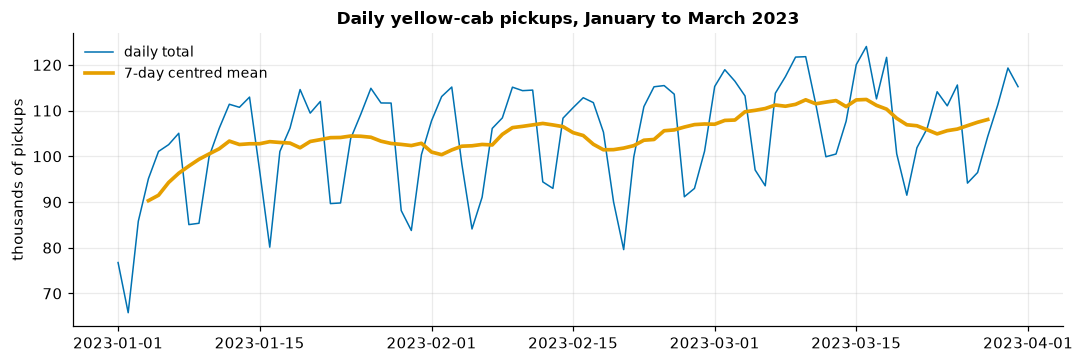

hour                       Jan        Feb        Mar
mean pickups per day 98,926.00 104,068.00 109,946.00


In [3]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(daily.index, daily / 1000, lw=1, label="daily total")
ax.plot(daily.index, daily.rolling(7, center=True).mean() / 1000, lw=2.4, label="7-day centred mean")
ax.set(title="Daily yellow-cab pickups, January to March 2023", ylabel="thousands of pickups"); ax.legend()
plt.tight_layout(); plt.show()
print(daily.groupby(daily.index.month).mean().round(0).rename(lambda m: ["Jan", "Feb", "Mar"][m - 1]).to_frame("mean pickups per day").T)

There is a clear **upward drift**: the average day in March has about 11% more pickups than in January. Over three months we cannot say whether that is a long-run trend, a seasonal recovery from the post-holiday winter lull, or a mix. That is a real limit of short histories: **you cannot estimate a yearly seasonal pattern from less than two years of data**, so we do not try.

The weekly saw-tooth is the *weekly seasonality*, and the dips are holidays.

## 2. Decomposing hourly demand with two seasons

Hourly demand has two cycles at once: a daily one (period 24) and a weekly one (period 168). `MSTL` (multiple seasonal-trend decomposition using Loess) peels off several seasonal periods in turn.

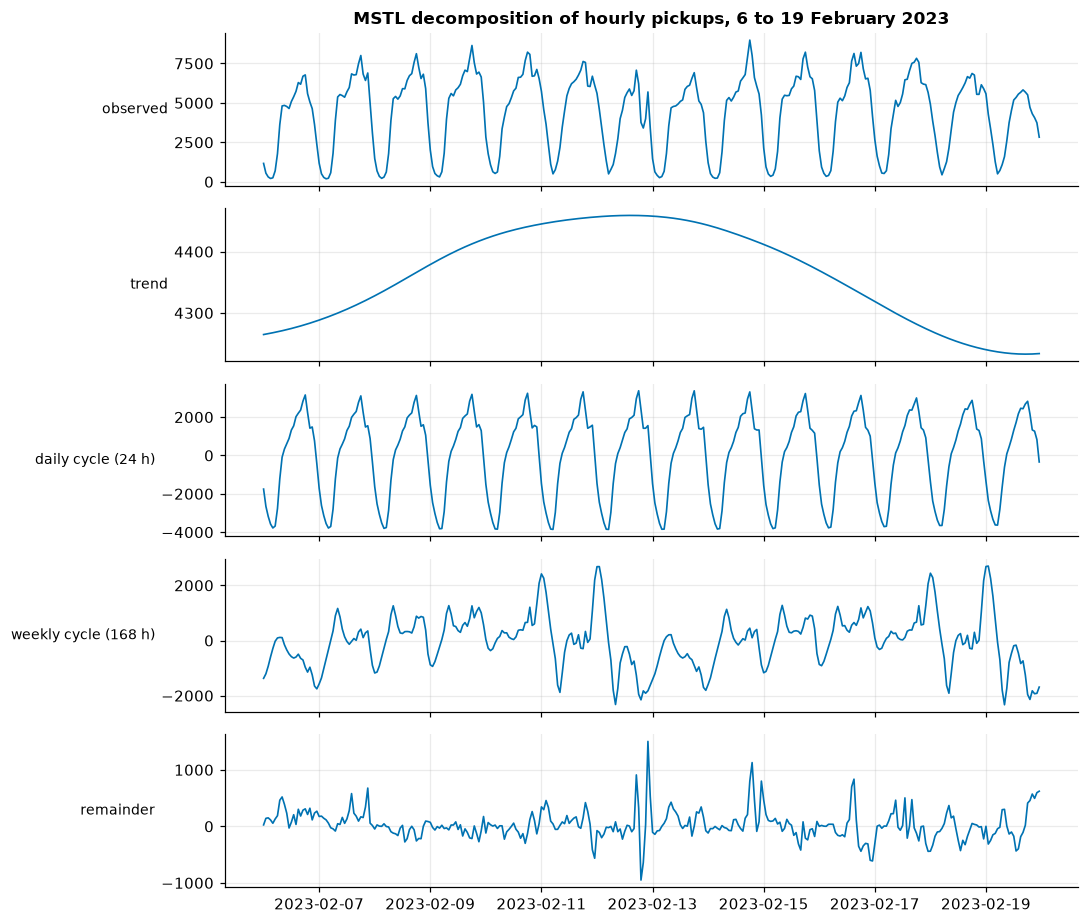

In [4]:
fit = MSTL(y, periods=(24, 168)).fit()
parts = pd.DataFrame({"observed": y, "trend": fit.trend,
                      "daily cycle (24 h)": fit.seasonal["seasonal_24"],
                      "weekly cycle (168 h)": fit.seasonal["seasonal_168"],
                      "remainder": fit.resid})

zoom = slice("2023-02-06", "2023-02-19")                 # two ordinary weeks
fig, axes = plt.subplots(5, 1, figsize=(10, 8.5), sharex=True)
for ax, col in zip(axes, parts.columns):
    ax.plot(parts.loc[zoom, col].index, parts.loc[zoom, col].to_numpy(), lw=1.1)
    ax.set_ylabel(col, rotation=0, ha="right", va="center", fontsize=9)
axes[0].set_title("MSTL decomposition of hourly pickups, 6 to 19 February 2023")
plt.tight_layout(); plt.show()

Read the panels top to bottom. The **daily cycle** repeats identically every day. The **weekly cycle** is smaller but changes the daily shape between weekdays and weekends. The trend is nearly flat over two weeks. The **remainder** is what is left, and it is small next to the observed series.

How much of the variation does each part explain? Variances of components do not add up to exactly the total, because the parts are correlated with each other, but the shares are still a good guide.

In [5]:
shares = (parts.drop(columns="observed").var() / parts["observed"].var()).round(3)
print(shares.to_string())
print(f"\nstd of the series: {y.std():,.0f} pickups per hour;  std of the remainder: {fit.resid.std():,.0f}")
assert shares["daily cycle (24 h)"] > 0.7 and shares["remainder"] < 0.05

trend                  0.01
daily cycle (24 h)     0.82
weekly cycle (168 h)   0.15
remainder              0.01

std of the series: 2,431 pickups per hour;  std of the remainder: 252


The daily cycle accounts for roughly four-fifths of the variance, the weekly cycle for about one seventh, the trend and the remainder only about a percent each. After removing the two cycles the typical error is about 250 pickups an hour against a spread of about 2,400 in the raw series: a forecast that gets the cycles right is already close, **and almost all of the forecasting skill lies in the seasonal structure**. Keep that in mind when the models arrive.

<div class="admonition note">
<p class="admonition-title">Decomposition is a description, not a forecast</p>
<p>MSTL looks at the whole series, including the future of each point (it is a smoother). That is fine for understanding the data, and <em>wrong</em> for building features that a model will use at prediction time. For forecasting, every number must be computable from the past alone.</p>
</div>

## 3. Autocorrelation: how much does the past say about now?

The **autocorrelation function** gives, for each lag $k$, the correlation between $y_t$ and $y_{t-k}$. It shows both the memory of the series and its seasonal periods.

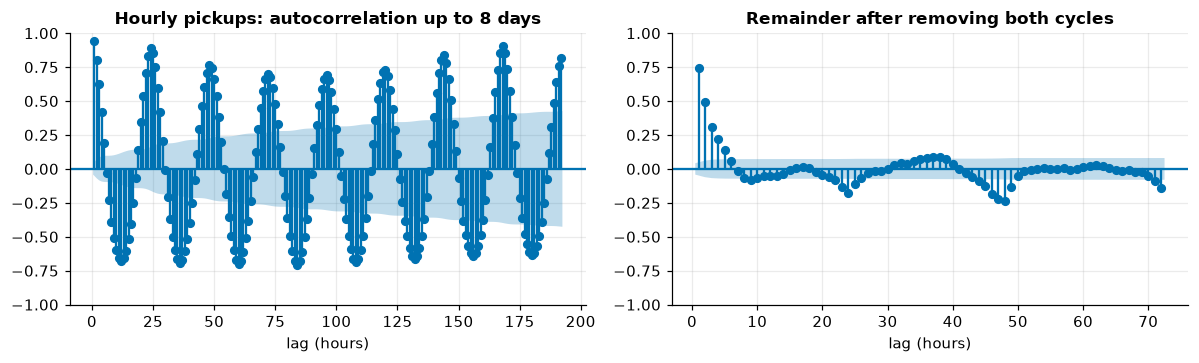

pickups:   lag 1 = 0.94, lag 12 = -0.68, lag 24 = 0.89, lag 168 = 0.90
remainder: lag 1 = 0.74, lag 2 = 0.49, lag 24 = -0.17


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
plot_acf(y, lags=24 * 8, ax=axes[0], zero=False, title="Hourly pickups: autocorrelation up to 8 days")
plot_acf(fit.resid, lags=24 * 3, ax=axes[1], zero=False, title="Remainder after removing both cycles")
for ax in axes: ax.set_xlabel("lag (hours)")
plt.tight_layout(); plt.show()

a = acf(y, nlags=168)
r = acf(fit.resid, nlags=48)
print("pickups:   lag 1 = %.2f, lag 12 = %.2f, lag 24 = %.2f, lag 168 = %.2f" % (a[1], a[12], a[24], a[168]))
print("remainder: lag 1 = %.2f, lag 2 = %.2f, lag 24 = %.2f" % (r[1], r[2], r[24]))

Left: the correlation swings up and down with a 24-hour rhythm; at 12 hours it is strongly **negative** (day versus night) and at 24 hours strongly positive. The value at lag 168 is as high as at lag 24, so **the same hour last week is as informative as the same hour yesterday**, and it also has the right weekday.

Right: the remainder is *not* white noise. Its lag-1 autocorrelation is about 0.74: if demand is a bit above the pattern this hour, it is probably above it next hour too (a rainy evening, a concert letting out). That short-run momentum is information a model can use, **but only when the forecast is made one hour ahead**. When forecasting a full day ahead, those recent values are not yet known, a point that returns on the feature-engineering and backtesting pages.

## 4. Stationarity

A series is (weakly) **stationary** if its mean and variance are constant over time and the correlation between two points depends only on the gap between them. Classical models such as ARIMA are built for stationary series. Trend and seasonality break stationarity, because the mean moves.

Two standard tests, which ask opposite questions:

- **ADF** (augmented Dickey-Fuller): the null hypothesis is a *unit root* (non-stationary). A **small** p-value rejects it, which suggests stationarity.
- **KPSS**: the null hypothesis is *stationary*. A **small** p-value rejects it, which suggests non-stationarity.

Run both on several versions of the series.

In [7]:
def stationarity(name, s):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                    # KPSS warns when its p-value is off its lookup table
        adf_p = adfuller(s, autolag="AIC")[1]
        kpss_p = kpss(s, regression="c", nlags="auto")[1]
    verdict = {(True, True): "stationary (both agree)", (False, False): "NOT stationary (both agree)"}.get(
        (adf_p < 0.05, kpss_p >= 0.05), "tests disagree")
    return {"series": name, "ADF p": adf_p, "KPSS p": kpss_p, "verdict": verdict}

table = pd.DataFrame([
    stationarity("daily totals", daily),
    stationarity("daily totals, differenced once", daily.diff().dropna()),
    stationarity("daily totals, seasonal difference (7)", daily.diff(7).dropna()),
    stationarity("hourly pickups", y),
    stationarity("hourly, seasonal difference (24)", y.diff(24).dropna()),
    stationarity("hourly, seasonal difference (168)", y.diff(168).dropna()),
]).set_index("series")
table.style.format({"ADF p": "{:.4f}", "KPSS p": "{:.3f}"})

,ADF p,KPSS p,verdict
series,,,
daily totals,0.1206,0.010,NOT stationary (both agree)
"daily totals, differenced once",0.0000,0.100,stationary (both agree)
"daily totals, seasonal difference (7)",0.0011,0.100,stationary (both agree)
hourly pickups,0.0000,0.010,tests disagree
"hourly, seasonal difference (24)",0.0000,0.100,stationary (both agree)
"hourly, seasonal difference (168)",0.0000,0.018,tests disagree


(KPSS reports p-values only between 0.01 and 0.10; a printed 0.010 means "0.01 or smaller" and 0.100 means "0.10 or larger".)

Several lessons are in this table.

1. **Daily totals**: ADF cannot reject a unit root and KPSS rejects stationarity. Both say *not stationary*, as the drift and the weekly cycle suggest.
2. **Differencing fixes it.** Replacing each value with its change from the previous one (or from the same weekday last week) gives a series both tests accept as stationary.
3. **The hourly series is a case where the tests disagree.** ADF rejects a unit root while KPSS rejects stationarity. A strong *deterministic* seasonal pattern is not a unit root, so ADF is satisfied, but the mean is certainly not constant over the day, so KPSS objects. When tests disagree, trust the plot and the context, not one p-value.
4. Subtracting the value 24 hours ago removes the daily cycle and both tests are satisfied. Subtracting the value 168 hours ago, which also removes the weekly cycle, leaves ADF satisfied but KPSS still objecting (p = 0.018): the upward drift is still there. Even a good seasonal difference does not settle the question.

<div class="admonition warning">
<p class="admonition-title">Do not over-trust these tests</p>
<p>With 90 days of data the tests have limited power, p-values are sensitive to the number of lags tried, and "stationary" is a property of a model assumption, not a fact about the world. Use them to <em>guide</em> decisions such as how much to difference, then judge the decision by out-of-sample forecast error (the backtesting page).</p>
</div>

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| Trend estimated from 3 months "keeps rising" | too short to separate trend from yearly seasonality | state the limit; do not extrapolate a trend you cannot tell from a season |
| Decomposition used as a model feature | smoothers use the future | compute features only from the past (lags, causal rolling windows) |
| ADF and KPSS disagree | seasonality is not a unit root; low power | look at the plot, difference as needed, judge by forecast error |
| Multiplicative pattern fitted additively | seasonal swing grows with the level | model the log of the series |
| Autocorrelation plot looks cyclic | seasonality | read the lag of the peaks: they are the periods |

## Check yourself

<details class="question">
<summary>1. The autocorrelation of the hourly series at lag 12 is strongly negative. Why?</summary>

Twelve hours apart is day versus night: a busy afternoon hour pairs with a quiet small-hours hour, so when one is above the mean the other tends to be below. A negative value at half the period is a typical signature of a strong cycle.

</details>

<details class="question">
<summary>2. The remainder's lag-1 autocorrelation is 0.74. Does this mean you can forecast tomorrow's remainder well?</summary>

No. It means the remainder one hour ahead is predictable **once you have seen this hour**. Forecasting a whole day ahead you do not know today's recent remainders for the hours you are predicting, and the correlation decays with the lag (it was already down to 0.49 at lag 2). Predictability depends on the *forecast horizon*, not just on the series.

</details>

<details class="question">
<summary>3. A colleague says: ‘ADF p < 0.05 so the series is stationary, no need to difference.’ What do you ask?</summary>

Ask what **KPSS** says, what the **plot** shows, and what the test was run on. ADF's null is a unit root, so rejecting it does not prove a constant mean: a strongly seasonal series can pass ADF and still have a clearly time-varying mean, as the hourly row above shows. Then check whether differencing improves out-of-sample error rather than relying on the test.

</details>

## Exercises

<details class="question">
<summary>Decompose the <em>daily</em> series with <code>STL(daily, period=7, robust=True)</code> and report the weekly pattern as a table. Which weekday is quietest and which is busiest? Does anything about the answer give you pause?</summary>

```python
stl = STL(daily, period=7, robust=True).fit()
week = stl.seasonal.groupby(stl.seasonal.index.day_name()).mean().round(0)
print(week.sort_values())
```

The quietest weekday is **Monday** (about 16,000 pickups below the level, with Sunday next at about 13,000 below) and the busiest is **Thursday** (about 10,000 above, with Saturday and Friday close behind). Pause: three of the thirteen Mondays in the sample were public holidays (2 January, 16 January, 20 February), which pulls the Monday figure down. The seasonal estimate mixes *weekday* and *holiday* effects, which is why holidays become explicit inputs on the last page of this track.

</details>

<details class="question">
<summary>How much does seasonal differencing at lag 168 reduce the standard deviation of the hourly series? What does that say about a forecast that simply repeats last week?</summary>

```python
print(y.std(), y.diff(168).std(), y.diff(168).std() / y.std())
```

The standard deviation falls from about 2,430 to about 520, roughly a fifth of the original. The differenced series is the error of the forecast "same hour last week" (up to sign), so that trivial forecast already removes about four fifths of the spread. Any model has to beat this very strong baseline, and the next page turns it into a proper benchmark.

</details>

<details class="question">
<summary>Take the logarithm of the hourly series (add 1 to avoid log of zero if needed) and check whether the weekly seasonal amplitude looks more constant across months than in the raw series.</summary>

```python
for name, s in [("raw", y), ("log", np.log(y))]:
    amp = s.groupby(s.index.month).apply(lambda m: m.groupby([m.index.dayofweek, m.index.hour]).mean().std())
    print(name, amp.round(3).to_dict())
```

The raw weekly-pattern amplitude grows month by month (about 2,320, 2,400, 2,490 pickups, up 7%, tracking the 11% rise in the level), while the logged version is flat (about 0.98 each month). So the seasonal swing scales with the level: the pattern is mildly **multiplicative**, and modelling the log of demand would remove the interaction. With a difference this small an additive model is still adequate, which is why we keep the raw scale for readability.

</details>

## Recap

- A series is trend + seasonality + remainder; **here the two seasons (daily, weekly) carry nearly all the variance**.
- `MSTL` handles several seasonal periods. Decompositions describe; they must not be used as features, because they look at the future.
- **ACF** reveals memory and periods. The remainder still has short-run memory, usable only at short horizons.
- **Stationarity**: ADF and KPSS ask opposite questions, and can disagree. Differencing (ordinary or seasonal) is the standard remedy.
- Three months cannot support a trend or a yearly pattern claim.

**Next:** *Baselines: the forecasts to beat*.